<a href="https://colab.research.google.com/github/DeepFluxion/2026_2_IBMEC_PROG_ANALISE_DADOS/blob/main/notebooks/Aula_2026_10_21_PCA_e_KMeans.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src="https://www.institutomillenium.org.br/wp-content/uploads/2024/02/logo-ibmec-topo-rj-450x150.png.webp" width=300>

# Programação para Análise de Dados

## Aula 3 — PCA e Clusterização com K-means

**Duração:** 1h50 · **Bibliotecas:** `numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`

| Bloco | Tema | Tempo |
|---|---|---|
| 1 | Preparação do ambiente | 5 min |
| 2 | PCA com dados sintéticos | 20 min |
| 3 | PCA no dataset Iris | 15 min |
| 4 | K-means com dados sintéticos | 25 min |
| 5 | K-means no Iris | 10 min |
| 6 | PCA + K-means no Breast Cancer | 20 min |
| 7 | Exercícios e fechamento | 15 min |

> **Diferença importante em relação às aulas 1 e 2:** aqui **não existe uma resposta certa** para o modelo aprender. PCA e K-means são técnicas **não supervisionadas**: elas procuram **estrutura** nos dados sozinhas.

> **Como usar este notebook:** antes de cada bloco de código há uma explicação e a lista **"Linha a linha"**. Dentro do código, cada linha também tem um comentário `# ...`. Execute as células **em ordem**, com `Shift + Enter`.

# 🧰 Bloco 1 — Preparação do ambiente (5 min)

### Importando as bibliotecas

Rode a célula abaixo. Se aparecer "Ambiente pronto!", está tudo certo.

**🔍 Linha a linha**

- `import numpy as np`, `pandas as pd`, `matplotlib.pyplot as plt`, `seaborn as sns`: as bibliotecas de sempre, com apelidos curtos.
- `from sklearn.decomposition import PCA`: traz o **PCA** (análise de componentes principais).
- `from sklearn.cluster import KMeans`: traz o **K-means** (agrupamento).
- `StandardScaler`: padroniza as variáveis (as duas técnicas usam distâncias e variações, por isso a escala importa).
- As demais linhas configuram avisos, estilo e tamanho dos gráficos e guardam 4 cores.

In [1]:
import numpy as np                                    # numpy: contas com números e sorteios aleatórios
import pandas as pd                                   # pandas: tabelas de dados (DataFrame)
import matplotlib.pyplot as plt                       # matplotlib: gráficos
import seaborn as sns                                 # seaborn: estilo dos gráficos
from sklearn.decomposition import PCA                 # PCA: reduz o número de variáveis
from sklearn.cluster import KMeans                    # K-means: agrupa os dados em clusters
from sklearn.preprocessing import StandardScaler      # coloca as variáveis na mesma escala
import warnings                                       # avisos do Python
warnings.filterwarnings('ignore')                     # esconde avisos para a saída ficar limpa

sns.set_theme(style='whitegrid')                      # estilo visual dos gráficos
plt.rcParams['figure.figsize'] = (7, 4.5)             # tamanho padrão dos gráficos

AZUL, OURO, VERM, CINZA = '#16273E', '#F4AC02', '#C0392B', '#8C8C8C'   # cores que usaremos
print('Ambiente pronto!')                             # mensagem de confirmação

Ambiente pronto!


# 📸 Bloco 2 — PCA com dados sintéticos (20 min)

## O problema: variáveis demais
Imagine uma tabela com **30 colunas**. Impossível desenhar em um gráfico! E muitas colunas costumam ser **redundantes** (carregam a mesma informação).

## A ideia do PCA
> **Analogia:** você quer fotografar uma escultura 3D e guardá-la em uma foto 2D. Se escolher um **ângulo ruim**, perde detalhes; no **melhor ângulo**, a foto preserva o máximo da escultura.

O **PCA** (*Principal Component Analysis*) encontra os **melhores "ângulos"** para olhar os dados. Cada ângulo é um **componente principal (PC)**:

- **PC1**: a direção em que os dados **mais variam** (a mais informativa).
- **PC2**: a segunda direção que mais varia, **perpendicular** à PC1.
- E assim por diante.

Aqui **"informação" = variação (variância)**. Se mantivermos só os primeiros componentes, resumimos muitas colunas em poucas, **perdendo pouco**.

A **variância explicada** diz quanto da informação cada componente guarda (por exemplo: PC1 guarda 95%, PC2 guarda 5%).

## Nosso exemplo
Altura e peso de 100 pessoas: duas variáveis **muito correlacionadas** (quem é mais alto tende a pesar mais), ou seja, **redundantes**. Dá para resumi-las em **uma só** quase sem perder nada!

### Criando os dados

Peso depende da altura mais uma variação própria de cada pessoa.

**🔍 Linha a linha**

- `altura = rng.normal(170, 10, n)`: 100 alturas em forma de sino, média 170 e desvio 10.
- `peso = 70 + 0.9 * (altura - 170) + ...`: o peso médio é 70 kg e sobe 0,9 kg por cm acima de 170; o último termo é a variação individual.
- `.corr(...)`: correlação entre as duas colunas (próxima de 1 = muito redundantes).

In [2]:
rng = np.random.default_rng(42)                        # gerador aleatório com semente 42
n = 100                                                # 100 pessoas
altura = rng.normal(170, 10, n)                        # alturas: média 170 cm, desvio 10
peso = 70 + 0.9 * (altura - 170) + rng.normal(0, 5, n) # peso aumenta com a altura, mais uma variação aleatória

df_corpo = pd.DataFrame({'altura_cm': altura.round(1),  # monta a tabela: coluna da altura
                         'peso_kg': peso.round(1)})     # coluna do peso
print('Correlação altura × peso:', round(df_corpo['altura_cm'].corr(df_corpo['peso_kg']), 2))   # r entre as duas
df_corpo.head()                                        # primeiras linhas

Correlação altura × peso: 0.84


,altura_cm,peso_kg
0,173.0,70.9
1,159.6,67.1
2,177.5,75.0
3,179.4,82.2
4,150.5,47.8


### Padronizando e treinando o PCA

Antes do PCA, padronizamos: sem isso, a variável de escala maior (peso ou altura?) dominaria.

**🔍 Linha a linha**

- `StandardScaler().fit_transform(...)`: padroniza cada coluna (como na Aula 2).
- `PCA(n_components=2)`: cria o PCA pedindo **2 componentes** (como a tabela tem 2 colunas, ele os calcula todos).
- `pca.fit_transform(dados_pad)`: **fit** = descobre as direções (PC1, PC2); **transform** = reescreve cada pessoa nas novas coordenadas.
- `pca.explained_variance_ratio_`: lista com a **fração da variância** (informação) de cada componente; a soma é 1 (=100%).
- Resultado: PC1 guarda ≈ 92% da informação. Quase tudo cabe em **uma só** coluna!

In [3]:
scaler = StandardScaler()                              # cria o padronizador
dados_pad = scaler.fit_transform(df_corpo)             # padroniza as duas colunas (média 0, desvio 1)

pca = PCA(n_components=2)                              # cria o PCA para calcular 2 componentes
componentes = pca.fit_transform(dados_pad)             # aprende os componentes e já converte os dados para o novo "ângulo"

print('Variância explicada por componente:', pca.explained_variance_ratio_.round(3))   # fração de informação de cada PC
print(f'PC1 guarda {pca.explained_variance_ratio_[0]*100:.1f}% da informação')          # em porcentagem

Variância explicada por componente: [0.918 0.082]
PC1 guarda 91.8% da informação


### Visualizando os componentes

À esquerda, os dados originais (padronizados) com a direção da PC1. À direita, os mesmos dados nas novas coordenadas.

**🔍 Linha a linha**

- `dados_pad[:, 0]`: todas as linhas da coluna 0 (altura padronizada); `[:, 1]` é o peso. (O `:` significa "todas as linhas".)
- `pca.components_[0]`: o vetor que aponta na direção da PC1; multiplicamos por 3 só para a linha ficar comprida.
- `plt.plot([-d0, d0], [-d1, d1])`: traça uma linha que atravessa o centro (0, 0) na direção da PC1.
- `componentes[:, 0]` e `[:, 1]`: as coordenadas de cada pessoa **depois** do PCA (PC1 e PC2).
- `set_aspect('equal', adjustable='datalim')`: deixa os dois eixos na mesma escala, para a nuvem não parecer distorcida.

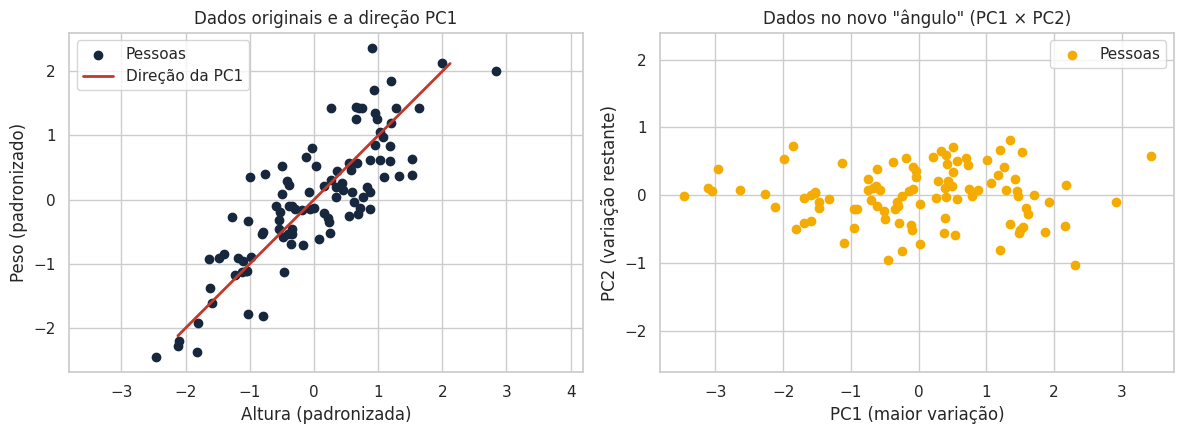

In [4]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))      # 2 gráficos lado a lado

eixos[0].scatter(dados_pad[:, 0], dados_pad[:, 1], color=AZUL, label='Pessoas')   # dados originais padronizados
direcao = pca.components_[0] * 3                        # vetor da PC1, esticado para ficar visível
eixos[0].plot([-direcao[0], direcao[0]], [-direcao[1], direcao[1]],   # linha que passa pelo centro na direção da PC1
              color=VERM, linewidth=2, label='Direção da PC1')       # cor, espessura e legenda
eixos[0].set_title('Dados originais e a direção PC1')   # título 1
eixos[0].set_xlabel('Altura (padronizada)')             # eixo x
eixos[0].set_ylabel('Peso (padronizado)')               # eixo y
eixos[0].legend()                                       # legenda
eixos[0].set_aspect('equal', adjustable='datalim')      # mesma escala nos dois eixos (não distorce ângulos)

eixos[1].scatter(componentes[:, 0], componentes[:, 1], color=OURO, label='Pessoas')   # dados nas novas coordenadas
eixos[1].set_title('Dados no novo "ângulo" (PC1 × PC2)')   # título 2
eixos[1].set_xlabel('PC1 (maior variação)')             # eixo x
eixos[1].set_ylabel('PC2 (variação restante)')          # eixo y
eixos[1].legend()                                       # legenda
eixos[1].set_aspect('equal', adjustable='datalim')      # mesma escala nos dois eixos
plt.tight_layout()                                      # evita sobreposição
plt.show()                                              # exibe

👀 **Leitura:**
- À esquerda: a linha vermelha (PC1) acompanha o **comprimento** da nuvem, a direção de maior variação.
- À direita: após o PCA, a nuvem fica **deitada**: quase toda a variação está no eixo PC1; no PC2 ela é pequena. Por isso podemos **descartar o PC2** e ficar só com PC1.

### Resumindo duas colunas em uma

Pedimos só 1 componente: cada pessoa passa a ser descrita por **um único número**.

**🔍 Linha a linha**

- `PCA(n_components=1)`: ficamos só com a PC1.
- `.shape`: mostra (número de linhas, número de colunas). Passamos de 2 colunas para 1.
- Mantivemos ≈ 92% da informação com **metade das colunas**. Em datasets com 30 colunas, essa economia é enorme.

In [5]:
pca1 = PCA(n_components=1)                             # PCA com apenas 1 componente
resumo = pca1.fit_transform(dados_pad)                 # cada pessoa vira um único número
print('Formato antes :', dados_pad.shape)              # (100 pessoas, 2 colunas)
print('Formato depois:', resumo.shape)                 # (100 pessoas, 1 coluna)
print(f'Informação mantida: {pca1.explained_variance_ratio_[0]*100:.1f}%')   # quanto da informação sobrou

Formato antes : (100, 2)
Formato depois: (100, 1)
Informação mantida: 91.8%


# 🌸 Bloco 3 — PCA no dataset Iris (15 min)

O **Iris** tem 150 flores de 3 espécies e **4 medidas** (comprimento e largura da sépala e da pétala). Não dá para desenhar 4 dimensões, mas dá para desenhar **2**. Vamos usar o PCA para resumir as 4 medidas em 2 componentes e **ver** as flores.

> O PCA **não usa** a espécie. Usaremos a espécie só para **pintar** os pontos e conferir se o PCA preservou a estrutura.

### PCA no Iris

Carregamos, padronizamos e aplicamos o PCA com 2 componentes.

**🔍 Linha a linha**

- `iris.data`: só as 4 medidas; `iris.target`: a espécie de cada flor (usada apenas para colorir).
- `StandardScaler().fit_transform(X_iris)`: padroniza as 4 colunas em uma linha (cria o padronizador e aplica).
- `PCA(n_components=2)` e `.fit_transform(...)`: resumem as 4 colunas em 2.
- `.explained_variance_ratio_.sum()`: soma das frações: quanto as 2 PCs, juntas, preservam. Aqui, ≈ 96%.

In [6]:
from sklearn.datasets import load_iris                 # função que carrega o Iris

iris = load_iris(as_frame=True)                        # carrega como tabela do pandas
X_iris = iris.data                                     # as 4 medidas (sem a espécie)
especie = iris.target                                  # a espécie (0, 1, 2), só para colorir depois
nomes_especies = [str(e) for e in iris.target_names]   # nomes das espécies, como texto

X_iris_pad = StandardScaler().fit_transform(X_iris)    # padroniza as 4 medidas
pca_iris = PCA(n_components=2)                         # PCA com 2 componentes
pcs_iris = pca_iris.fit_transform(X_iris_pad)          # converte as 150 flores para (PC1, PC2)

print('Variância explicada:', pca_iris.explained_variance_ratio_.round(3))   # fração de cada PC
print(f'As 2 primeiras PCs guardam {pca_iris.explained_variance_ratio_.sum()*100:.1f}% da informação')   # soma

Variância explicada: [0.73  0.229]
As 2 primeiras PCs guardam 95.8% da informação


### Mapa das flores em 2 dimensões

Cada ponto é uma flor, pintada pela espécie.

**🔍 Linha a linha**

- `marcador = (especie == codigo)`: uma lista de verdadeiro/falso, marcando quais flores são da espécie da vez.
- `pcs_iris[marcador, 0]`: a PC1 apenas das flores marcadas; `[marcador, 1]` é a PC2.
- Resultado: as espécies aparecem **separadas** (a setosa bem isolada), mesmo o PCA não conhecendo as espécies!

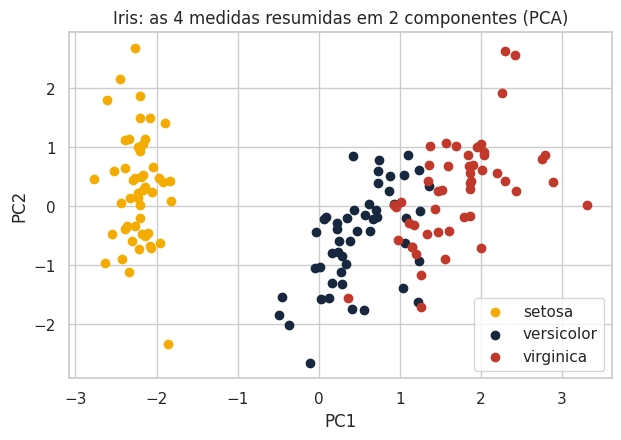

In [7]:
cores_especies = [OURO, AZUL, VERM]                    # uma cor para cada espécie
for codigo in [0, 1, 2]:                               # para cada espécie
    marcador = (especie == codigo)                     # True para as flores dessa espécie
    plt.scatter(pcs_iris[marcador, 0], pcs_iris[marcador, 1],   # PC1 (x) e PC2 (y) dessas flores
                color=cores_especies[codigo], label=nomes_especies[codigo])   # cor e legenda
plt.title('Iris: as 4 medidas resumidas em 2 componentes (PCA)')   # título
plt.xlabel('PC1')                                      # eixo x
plt.ylabel('PC2')                                      # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe

### O que significa cada componente?

Cada PC é uma **mistura** das variáveis originais. A tabela mostra o "peso" de cada variável em cada PC.

**🔍 Linha a linha**

- `pca_iris.components_`: matriz com os pesos; cada linha é um componente, cada coluna uma variável original.
- `pd.DataFrame(..., columns=..., index=...)`: coloca nomes para facilitar a leitura.
- Leitura: na PC1, as medidas da **pétala** e o comprimento da sépala têm pesos grandes e do mesmo sinal: a PC1 funciona como um "**tamanho geral** da flor".

In [8]:
pesos = pd.DataFrame(pca_iris.components_,             # matriz com um componente por linha
                     columns=X_iris.columns,           # nomes das variáveis originais nas colunas
                     index=['PC1', 'PC2'])             # nomes dos componentes nas linhas
print(pesos.round(2))                                  # mostra os pesos com 2 casas decimais

     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
PC1               0.52             -0.27               0.58              0.56
PC2               0.38              0.92               0.02              0.07


### Quantos componentes manter?

Calculamos a variância de **todos** os componentes e o acumulado.

**🔍 Linha a linha**

- `PCA()`: sem número de componentes, calcula todos.
- `.fit(...)`: só aprende; usamos aqui porque só queremos a variância (não converter os dados).
- `.cumsum()`: soma acumulada. Ex.: [0,73; 0,23; ...] vira [0,73; 0,96; ...].
- `plt.bar(...)` desenha barras e `plt.plot(...)` a linha por cima; os dois podem estar no mesmo gráfico.
- Regra prática: guarde componentes até a acumulada chegar a ≈ 90–95%. No Iris, 2 componentes (≈ 96%) já bastam.

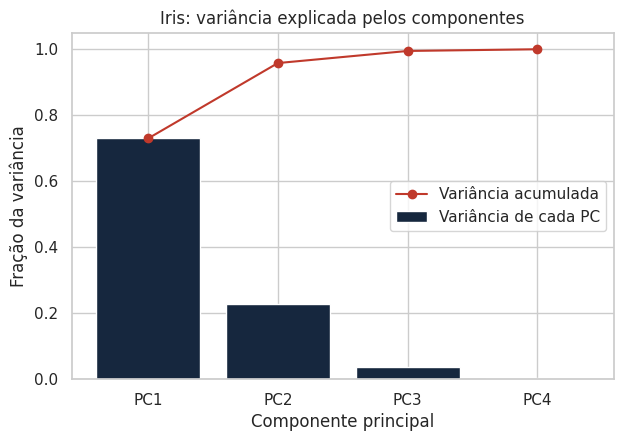

Acumulada: [0.73  0.958 0.995 1.   ]


In [9]:
pca_todos = PCA()                                      # sem n_components: calcula todos os componentes (4)
pca_todos.fit(X_iris_pad)                              # só aprende os componentes (sem converter os dados)
variancia = pca_todos.explained_variance_ratio_        # fração de cada componente
acumulada = variancia.cumsum()                         # soma acumulada: 1º, 1º+2º, 1º+2º+3º...
nomes_pc = ['PC1', 'PC2', 'PC3', 'PC4']                # nomes para o eixo x

plt.bar(nomes_pc, variancia, color=AZUL, label='Variância de cada PC')   # barras: variância de cada componente
plt.plot(nomes_pc, acumulada, color=VERM, marker='o', label='Variância acumulada')   # linha: soma acumulada
plt.title('Iris: variância explicada pelos componentes')   # título
plt.xlabel('Componente principal')                     # eixo x
plt.ylabel('Fração da variância')                      # eixo y
plt.legend(loc='center right')                         # legenda
plt.show()                                             # exibe
print('Acumulada:', acumulada.round(3))                # valores acumulados

# 🎯 Exercício 1 (5 min) — PCA com 3 componentes no Iris

**Desafio:** aplique `PCA(n_components=3)` aos dados padronizados do Iris (`X_iris_pad`). Mostre a variância explicada de cada componente e a **soma** dos três. Compare com os ≈ 96% que 2 componentes mantêm. **Vale a pena usar o terceiro componente?** Responda em uma frase.

In [10]:
# TODO: crie PCA(n_components=3), use .fit(X_iris_pad) e imprima .explained_variance_ratio_ e a soma

# 🎯 Bloco 4 — K-means com dados sintéticos (25 min)

## O problema: agrupar sem saber as classes
Na Aula 2 (KNN), **conhecíamos** a classe de cada fruta. Agora **não temos classes**: queremos que o computador **descubra grupos** de casos parecidos. Isso se chama **clusterização** (cluster = grupo). Exemplos: segmentar clientes, agrupar notícias parecidas.

## A ideia do K-means
> **Analogia:** você organiza uma festa e escolhe **K pontos de encontro** (K mesas). Cada convidado vai à mesa **mais próxima**. Depois, cada mesa **se muda para o centro** dos convidados que ficaram nela. Os convidados trocam de mesa se alguma ficou mais perto. Repete até ninguém mais trocar.

### Algoritmo
1. Você escolhe **K** (número de grupos).
2. O algoritmo sorteia **K centros** iniciais.
3. Cada ponto é atribuído ao **centro mais próximo**.
4. Cada centro **vai para a média** dos pontos do seu grupo.
5. Repete os passos 3 e 4 até os centros pararem de mudar.

> Os grupos são formados por **distância**, então a **padronização** é importante (como no KNN).

### Criando 3 grupos sintéticos

A função `make_blobs` do scikit-learn cria "bolhas" de pontos. Vamos esquecer quais pontos vieram de qual bolha.

**🔍 Linha a linha**

- `make_blobs(...)`: devolve **X** (as coordenadas) e os grupos reais (que **não** vamos dar ao K-means; só para conferência).
- `n_samples=150`, `centers=3`, `cluster_std=1.0`: quantos pontos, quantos grupos e o espalhamento.
- Pintamos tudo de **cinza** para simular a situação real: não sabemos de que grupo cada ponto veio.

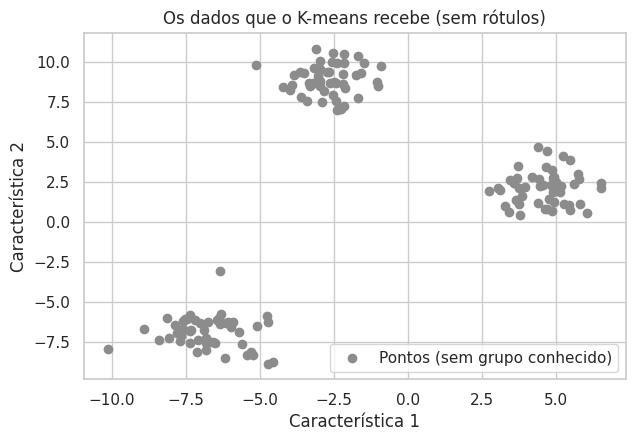

In [11]:
from sklearn.datasets import make_blobs               # função que cria grupos sintéticos de pontos

X_blobs, grupo_real = make_blobs(n_samples=150,        # 150 pontos no total
                                 centers=3,            # 3 grupos
                                 cluster_std=1.0,      # quão espalhado é cada grupo
                                 random_state=42)      # semente (resultado repetível)

plt.scatter(X_blobs[:, 0], X_blobs[:, 1], color=CINZA, label='Pontos (sem grupo conhecido)')   # todos cinza
plt.title('Os dados que o K-means recebe (sem rótulos)')   # título
plt.xlabel('Característica 1')                         # eixo x
plt.ylabel('Característica 2')                         # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe

### Aplicando o K-means

Pedimos 3 grupos. O algoritmo devolve o grupo (0, 1 ou 2) de cada ponto e a posição dos centros.

**🔍 Linha a linha**

- `KMeans(n_clusters=3, n_init=10, random_state=42)`: cria o modelo. **`n_clusters` é o K.** `n_init=10` repete o sorteio inicial 10 vezes para evitar uma largada ruim.
- `kmeans.fit_predict(X_blobs)`: aprende os grupos e já devolve uma lista com o **número do grupo** de cada ponto.
- `kmeans.cluster_centers_`: as posições dos centros (as "mesas").
- `np.bincount(grupos)`: conta quantos pontos há em cada grupo.
- `grupos == g`: lista de verdadeiro/falso que marca os pontos do grupo `g`; usamos para colorir cada grupo.
- `zip([0, 1, 2], [AZUL, OURO, VERM])`: percorre duas listas juntas (grupo 0 com azul, 1 com ouro, 2 com vermelho).

Grupo dos 10 primeiros pontos: [0 0 1 2 1 2 0 0 1 2]
Quantos pontos em cada grupo: [50 50 50]


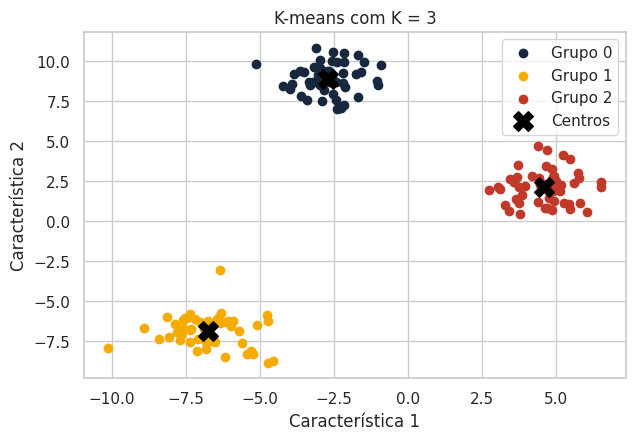

In [12]:
kmeans = KMeans(n_clusters=3,                          # número de grupos que queremos
                n_init=10,                             # roda 10 vezes com sorteios diferentes e fica com o melhor
                random_state=42)                       # semente (resultado repetível)
grupos = kmeans.fit_predict(X_blobs)                   # aprende os grupos e devolve o grupo de cada ponto
centros = kmeans.cluster_centers_                      # coordenadas dos 3 centros

print('Grupo dos 10 primeiros pontos:', grupos[:10])   # os 10 primeiros resultados
print('Quantos pontos em cada grupo:', np.bincount(grupos))   # contagem por grupo

for g, cor in zip([0, 1, 2], [AZUL, OURO, VERM]):      # para cada grupo e sua cor
    plt.scatter(X_blobs[grupos == g, 0], X_blobs[grupos == g, 1], color=cor, label=f'Grupo {g}')   # pontos do grupo
plt.scatter(centros[:, 0], centros[:, 1], color='black', marker='X', s=200, label='Centros')   # centros em X preto
plt.title('K-means com K = 3')                         # título
plt.xlabel('Característica 1')                         # eixo x
plt.ylabel('Característica 2')                         # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe

⚠️ **Os números dos grupos (0, 1, 2) são apenas etiquetas.** Rodando de novo, o "grupo 0" pode virar o "grupo 2". O que importa é **quais pontos ficam juntos**.

### E se não soubermos quantos grupos existem? O método do cotovelo

Quando K aumenta, os pontos ficam mais perto dos seus centros. A **inércia** é a soma das distâncias ao quadrado de cada ponto até o seu centro: **quanto menor, mais "coesos" os grupos**. Mas ela **sempre diminui** com mais grupos (no extremo, cada ponto seria um grupo!).

Por isso olhamos o gráfico da inércia × K e procuramos o **"cotovelo"**: o ponto a partir do qual aumentar K melhora **pouco**.

### Método do cotovelo

Rodamos o K-means para K de 1 a 8 e guardamos a inércia de cada um.

**🔍 Linha a linha**

- `range(1, 9)`: os números de 1 a 8.
- `km.fit(X_blobs)`: aprende os grupos (aqui não precisamos dos rótulos devolvidos).
- `km.inertia_`: a inércia do modelo. `inercias.append(...)` acrescenta o valor à lista.
- No gráfico, a curva cai muito até K = 3 e depois quase **estabiliza**: o cotovelo está em **K = 3**, o número de grupos que criamos.

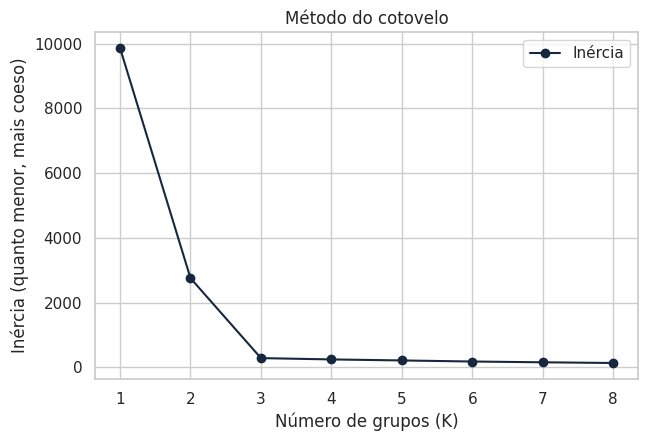

In [13]:
valores_k = range(1, 9)                                # testar K de 1 até 8
inercias = []                                          # lista vazia para guardar as inércias

for k in valores_k:                                    # repete para cada K
    km = KMeans(n_clusters=k, n_init=10, random_state=42)   # cria o K-means com esse K
    km.fit(X_blobs)                                    # aprende os grupos
    inercias.append(km.inertia_)                       # guarda a inércia

plt.plot(valores_k, inercias, color=AZUL, marker='o', label='Inércia')   # linha com bolinhas
plt.title('Método do cotovelo')                        # título
plt.xlabel('Número de grupos (K)')                     # eixo x
plt.ylabel('Inércia (quanto menor, mais coeso)')       # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe

# 🎯 Exercício 2 (5 min) — K = 3 ou K = 4?

**Desafio:** rode o K-means em `X_blobs` com **K = 3** e com **K = 4** e compare a **inércia** (`inertia_`) de cada um. A inércia caiu muito de K = 3 para K = 4? Isso indica que K = 4 é melhor? Responda em uma frase.

In [14]:
# TODO: crie dois KMeans (n_clusters=3 e n_clusters=4), faça .fit(X_blobs) e imprima .inertia_ de cada um

# 🌸 Bloco 5 — K-means no Iris (10 min)

Vamos agrupar as flores do Iris **sem usar as espécies**. Depois comparamos os grupos encontrados com as espécies reais para ver se o K-means "descobriu" a estrutura.

> **Atenção:** em projetos reais não temos as espécies, e a comparação não existe. Aqui ela serve só para **aprender** como o K-means se comporta.

### K-means no Iris

Usamos as 4 medidas padronizadas (`X_iris_pad`) e pedimos 3 grupos.

**🔍 Linha a linha**

- `km_iris.fit_predict(X_iris_pad)`: o K-means recebe só as 4 medidas, **sem** as espécies.
- `[nomes_especies[e] for e in especie]`: converte cada código (0, 1, 2) em nome da espécie.
- `pd.crosstab(a, b)`: **tabela cruzada**: conta quantas flores caem em cada combinação (espécie real × grupo).
- Leitura: a setosa fica quase toda em um grupo só. Versicolor e virginica se misturam um pouco, porque se parecem.

In [15]:
km_iris = KMeans(n_clusters=3, n_init=10, random_state=42)   # K-means com 3 grupos
grupos_iris = km_iris.fit_predict(X_iris_pad)          # grupo de cada flor (usando as 4 medidas)

tabela = pd.crosstab(pd.Series([nomes_especies[e] for e in especie], name='Espécie real'),   # linhas: espécie real
                     pd.Series(grupos_iris, name='Grupo K-means'))                            # colunas: grupo encontrado
print(tabela)                                          # mostra a tabela cruzada

Grupo K-means   0   1   2
Espécie real             
setosa          0  50   0
versicolor     39   0  11
virginica      14   0  36


### Comparando visualmente (no mapa do PCA)

Lado a lado: os grupos do K-means e as espécies reais, ambos no mapa em 2 dimensões.

**🔍 Linha a linha**

- Usamos o **mapa do PCA** (`pcs_iris`) como "tela" para desenhar, mas o K-means usou as 4 medidas originais padronizadas.
- `eixos[0]` é o gráfico da esquerda (K-means) e `eixos[1]` o da direita (espécies reais).
- Os dois mapas são parecidos: o K-means recuperou **quase** a estrutura real, sem conhecer as espécies. As cores podem ser diferentes (os números dos grupos são etiquetas).

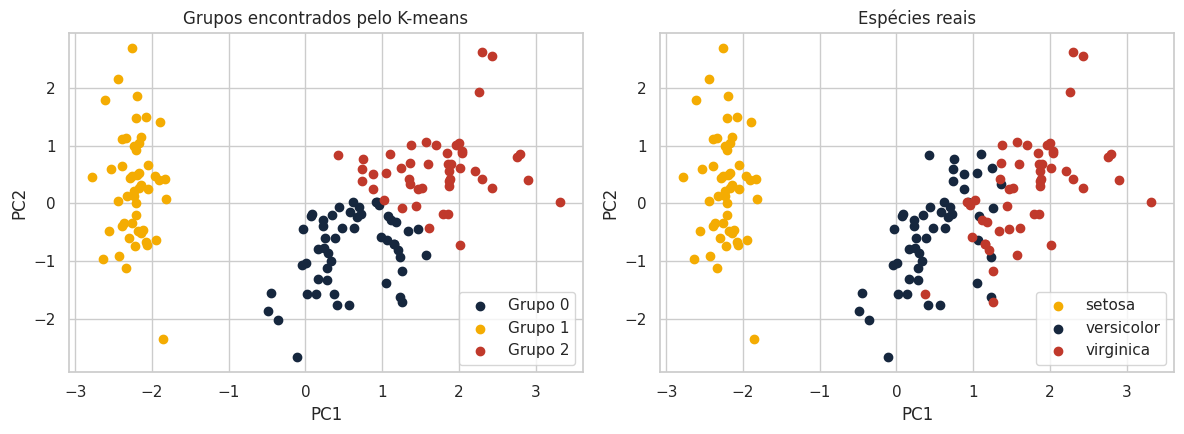

In [16]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4.5))      # 2 gráficos lado a lado

for g, cor in zip([0, 1, 2], [AZUL, OURO, VERM]):       # esquerda: grupos do K-means
    eixos[0].scatter(pcs_iris[grupos_iris == g, 0], pcs_iris[grupos_iris == g, 1], color=cor, label=f'Grupo {g}')
eixos[0].set_title('Grupos encontrados pelo K-means')   # título 1
eixos[0].set_xlabel('PC1')                              # eixo x
eixos[0].set_ylabel('PC2')                              # eixo y
eixos[0].legend()                                       # legenda

for g, cor in zip([0, 1, 2], [OURO, AZUL, VERM]):       # direita: espécies reais
    eixos[1].scatter(pcs_iris[especie == g, 0], pcs_iris[especie == g, 1], color=cor, label=nomes_especies[g])
eixos[1].set_title('Espécies reais')                    # título 2
eixos[1].set_xlabel('PC1')                              # eixo x
eixos[1].set_ylabel('PC2')                              # eixo y
eixos[1].legend()                                       # legenda
plt.tight_layout()                                      # evita sobreposição
plt.show()                                              # exibe

# 🩺 Bloco 6 — PCA + K-means no Breast Cancer (20 min)

Agora um dataset com **30 variáveis** (569 exames de tumores). Impossível desenhar em 30 dimensões, mas o **PCA** resolve! O roteiro:

1. **Padronizar** as 30 variáveis.
2. **PCA**: ver quantos componentes bastam e desenhar o mapa em 2D.
3. **K-means** com K = 2 e comparar com o diagnóstico real (maligno ou benigno), apenas para conferir.

Lembrete: **0 = maligno**, **1 = benigno**.

### Carregando e padronizando

Padronizar é essencial aqui: as variáveis têm escalas muito diferentes.

**🔍 Linha a linha**

- `cancer.data`: as 30 medidas; `cancer.target`: o diagnóstico (usaremos só para conferir).
- `X_cancer.shape`: (linhas, colunas) = (569, 30).
- `X_cancer_pad[:, 0].mean()` e `.std()`: média e desvio da primeira coluna padronizada (devem ser ≈ 0 e 1).

In [17]:
from sklearn.datasets import load_breast_cancer       # função que carrega o dataset

cancer = load_breast_cancer(as_frame=True)             # carrega como tabela
X_cancer = cancer.data                                 # as 30 medidas
diagnostico = cancer.target                            # 0 = maligno, 1 = benigno (só para conferir depois)

print('Formato dos dados:', X_cancer.shape)            # (569 exames, 30 variáveis)
X_cancer_pad = StandardScaler().fit_transform(X_cancer)   # padroniza as 30 variáveis
print('Média e desvio da 1ª variável após padronizar:',   # confirmação: média ~ 0 e desvio ~ 1
      X_cancer_pad[:, 0].mean().round(2), X_cancer_pad[:, 0].std().round(2))

Formato dos dados: (569, 30)
Média e desvio da 1ª variável após padronizar: -0.0 1.0


### Quantos componentes são necessários?

Com 30 colunas, a variância acumulada mostra quantas podemos descartar.

**🔍 Linha a linha**

- `range(1, 31)`: números de 1 a 30 (eixo x).
- `plt.axhline(0.90, ...)`: linha **h**orizontal de referência em 90%.
- `PCA(n_components=0.90)`: em vez de um número inteiro, damos uma **fração**: o PCA escolhe sozinho quantos componentes são necessários para guardar 90% da informação.
- `pca_90.n_components_`: quantos componentes ele escolheu (atributo com `_` no final = resultado calculado pelo modelo).
- Resultado: **7 componentes** guardam 90% da informação das 30 variáveis, e apenas 2 já guardam ≈ 63%.

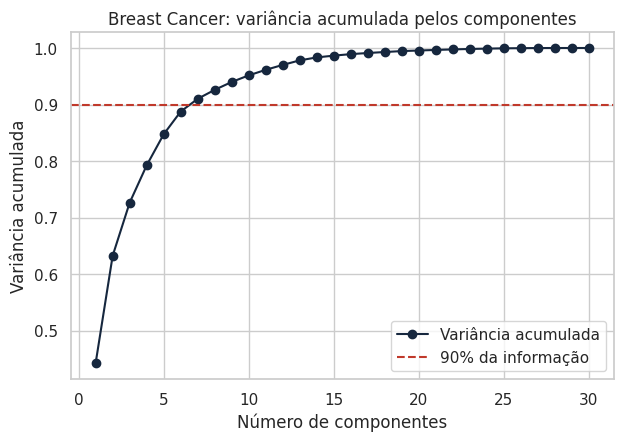

7 componentes guardam 90% da informação (de 30 variáveis!)
Só 2 componentes guardam 63.2%


In [18]:
pca_c = PCA()                                          # todos os componentes (30)
pca_c.fit(X_cancer_pad)                                # aprende os componentes
acum_c = pca_c.explained_variance_ratio_.cumsum()      # variância acumulada

plt.plot(range(1, 31), acum_c, color=AZUL, marker='o', label='Variância acumulada')   # curva acumulada
plt.axhline(0.90, color=VERM, linestyle='--', label='90% da informação')              # linha de referência em 90%
plt.title('Breast Cancer: variância acumulada pelos componentes')   # título
plt.xlabel('Número de componentes')                    # eixo x
plt.ylabel('Variância acumulada')                      # eixo y
plt.legend(loc='lower right')                          # legenda
plt.show()                                             # exibe

pca_90 = PCA(n_components=0.90)                        # um decimal = "guarde componentes até somar 90% da informação"
pca_90.fit(X_cancer_pad)                               # o próprio PCA decide quantos componentes precisa
print(f'{pca_90.n_components_} componentes guardam 90% da informação (de 30 variáveis!)')   # resultado
print(f'Só 2 componentes guardam {acum_c[1]*100:.1f}%')   # o que o mapa 2D preserva

### O mapa dos tumores em 2D

Cada ponto é um exame; as cores mostram o diagnóstico real (que o PCA não conhecia).

**🔍 Linha a linha**

- `PCA(n_components=2).fit_transform(...)`: reduz de 30 para 2 colunas.
- `alpha=0.6`: deixa os pontos um pouco transparentes (melhor para ver onde se sobrepõem).
- `pcs_c[diagnostico == 0, 0]`: PC1 apenas dos exames malignos (código 0).
- Mesmo sem conhecer o diagnóstico, o PCA colocou malignos e benignos em **regiões diferentes** do mapa.

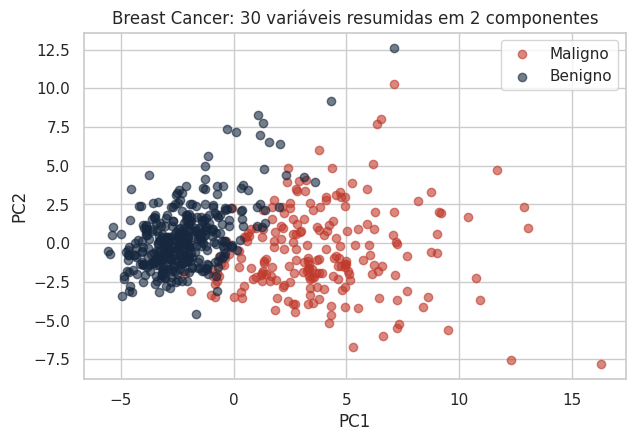

In [19]:
pca_2 = PCA(n_components=2)                            # PCA com 2 componentes
pcs_c = pca_2.fit_transform(X_cancer_pad)              # cada exame vira (PC1, PC2)

plt.scatter(pcs_c[diagnostico == 0, 0], pcs_c[diagnostico == 0, 1], color=VERM, alpha=0.6, label='Maligno')   # malignos
plt.scatter(pcs_c[diagnostico == 1, 0], pcs_c[diagnostico == 1, 1], color=AZUL, alpha=0.6, label='Benigno')   # benignos
plt.title('Breast Cancer: 30 variáveis resumidas em 2 componentes')   # título
plt.xlabel('PC1')                                      # eixo x
plt.ylabel('PC2')                                      # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe

### K-means com K = 2

Agrupamos os 569 exames em 2 grupos usando as 30 medidas padronizadas e comparamos com o diagnóstico.

**🔍 Linha a linha**

- `KMeans(n_clusters=2, ...)`: pedimos 2 grupos (sabemos que há duas classes, mas o K-means não sabe quais).
- `np.where(condição, 'Maligno', 'Benigno')`: cria uma lista de nomes conforme o código do diagnóstico.
- `pd.crosstab(...)`: conta quantos exames de cada diagnóstico caíram em cada grupo.
- Leitura: um grupo concentra quase todos os **malignos** e o outro quase todos os **benignos**. O K-means "descobriu" a separação **sem** ver o diagnóstico (não é perfeito: alguns exames caem no grupo "errado").

Grupo K-means       0    1
Diagnóstico real          
Benigno           339   18
Maligno            36  176


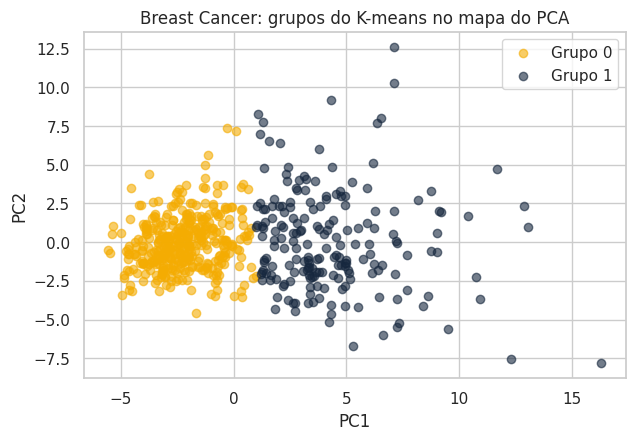

In [20]:
km_c = KMeans(n_clusters=2, n_init=10, random_state=42)   # K-means com 2 grupos
grupos_c = km_c.fit_predict(X_cancer_pad)              # grupo de cada exame (usando as 30 medidas)

tab_c = pd.crosstab(pd.Series(np.where(diagnostico == 0, 'Maligno', 'Benigno'), name='Diagnóstico real'),   # linhas
                    pd.Series(grupos_c, name='Grupo K-means'))                                              # colunas
print(tab_c)                                           # tabela cruzada

for g, cor in zip([0, 1], [OURO, AZUL]):               # desenha os grupos no mapa do PCA
    plt.scatter(pcs_c[grupos_c == g, 0], pcs_c[grupos_c == g, 1], color=cor, alpha=0.6, label=f'Grupo {g}')
plt.title('Breast Cancer: grupos do K-means no mapa do PCA')   # título
plt.xlabel('PC1')                                      # eixo x
plt.ylabel('PC2')                                      # eixo y
plt.legend()                                           # legenda
plt.show()                                             # exibe

# 🎯 Exercício 3 (5 min) — Iris com K = 2 e K = 3

**Desafio:** rode o K-means no `X_iris_pad` com **K = 2** e com **K = 3** e compare a **inércia** (`inertia_`) dos dois. Qual é menor? Isso significa que K = 3 é "melhor"? Explique em uma frase (use o método do cotovelo como argumento).

In [21]:
# TODO: crie dois KMeans (n_clusters=2 e n_clusters=3), faça .fit(X_iris_pad) e imprima .inertia_

# 🎯 Exercício 4 (5 min) — Breast Cancer com K = 3

**Desafio:** rode o K-means com **K = 3** em `X_cancer_pad` e monte a tabela cruzada com o diagnóstico (`diagnostico`), como no exemplo com K = 2. Como os malignos e benignos se distribuem pelos três grupos? Os grupos continuam fáceis de interpretar?

In [22]:
# TODO: KMeans(n_clusters=3, n_init=10, random_state=42) + fit_predict(X_cancer_pad) + pd.crosstab(...)

# 🏁 Bloco 7 — Fechamento (15 min)

## Resumo da aula

| Conceito | Em uma frase |
|---|---|
| **Aprendizado não supervisionado** | técnicas que procuram estrutura **sem** uma resposta certa |
| **PCA** | resume muitas variáveis em poucas (componentes), mantendo a maior parte da variação |
| **Componente principal** | direção de maior variação dos dados; PC1 > PC2 > PC3... |
| **Variância explicada** | quanto da informação cada componente guarda |
| **K-means** | agrupa os casos em K grupos pela **distância** aos centros |
| **Inércia e cotovelo** | ajudam a escolher K: procure onde a queda "estabiliza" |
| **Padronização** | essencial em PCA e K-means |

## Receitas

**PCA**
```python
X_pad = StandardScaler().fit_transform(X)          # 1. padronizar
pca = PCA(n_components=2)                          # 2. criar o PCA
componentes = pca.fit_transform(X_pad)             # 3. aprender e converter
print(pca.explained_variance_ratio_)               # 4. variância explicada
```

**K-means**
```python
km = KMeans(n_clusters=3, n_init=10, random_state=42)   # 1. criar (K = 3)
grupos = km.fit_predict(X_pad)                     # 2. aprender e obter o grupo de cada caso
print(km.inertia_)                                 # 3. inércia (para o cotovelo)
```

## Cuidados
- Os grupos do K-means **não são "verdades"**: dependem de K, da escala e da semente. Interprete olhando o **perfil** de cada grupo (por exemplo, a média de cada variável por grupo; veremos na Aula 4).
- Os componentes do PCA são **misturas** das variáveis originais; perdem a interpretação direta de cada coluna.

## 📝 Tarefa para casa
Aplique **PCA + K-means** ao dataset **Wine** (`from sklearn.datasets import load_wine`): padronize, veja a variância acumulada, desenhe o mapa em 2D, rode o K-means com K = 3 (o dataset tem 3 tipos de vinho) e compare com `wine.target` usando `pd.crosstab`.

# ✅ Gabarito dos exercícios

Respostas de todos os exercícios deste notebook. **Tente resolver antes de olhar!**

> As soluções abaixo são texto (não executam): copie o código para uma célula se quiser rodar.

## 🎯 Exercício 1 (5 min) — PCA com 3 componentes no Iris

**Resposta:** O terceiro componente acrescenta pouco (a soma passa de ≈ 96% para ≈ 99%). Dois componentes já resumem bem o Iris e permitem desenhar o mapa 2D.

**Código da solução:**

```python
pca3 = PCA(n_components=3)                              # PCA com 3 componentes
pca3.fit(X_iris_pad)                                    # aprende os componentes
print('Variância de cada componente:', pca3.explained_variance_ratio_.round(3))   # fração de cada PC
print(f'Soma dos 3 componentes: {pca3.explained_variance_ratio_.sum() * 100:.1f}%')   # informação mantida
```

## 🎯 Exercício 2 (5 min) — K = 3 ou K = 4?

**Resposta:** A inércia cai pouco de K = 3 para K = 4 (o 'cotovelo' está em K = 3). Logo, K = 4 não compensa: criaria um grupo a mais sem ganho real de coesão.

**Código da solução:**

```python
for k_ex in [3, 4]:                                     # testa os dois valores de K
    km_ex = KMeans(n_clusters=k_ex, n_init=10, random_state=42).fit(X_blobs)   # cria e treina
    print(f'K = {k_ex}: inércia = {km_ex.inertia_:.0f}')   # inércia de cada modelo
```

## 🎯 Exercício 3 (5 min) — Iris com K = 2 e K = 3

**Resposta (saída esperada):**

```text
K = 2: inércia = 222.4
K = 3: inércia = 139.8
A inércia sempre cai quando K aumenta; por isso olhamos o cotovelo, não o menor valor.
```

**Código da solução:**

```python
for k_ex in [2, 3]:                                     # testa os dois valores de K
    km_ex = KMeans(n_clusters=k_ex, n_init=10, random_state=42).fit(X_iris_pad)   # cria e treina
    print(f'K = {k_ex}: inércia = {km_ex.inertia_:.1f}')   # inércia
print('A inércia sempre cai quando K aumenta; por isso olhamos o cotovelo, não o menor valor.')   # lição
```

## 🎯 Exercício 4 (5 min) — Breast Cancer com K = 3

**Resposta:** Veja na tabela: normalmente um grupo concentra os malignos e dois dividem os benignos (ou um grupo fica 'misto'). Com K = 3 a leitura fica menos direta do que com K = 2, porque não existem 3 diagnósticos reais.

**Código da solução:**

```python
km3_c = KMeans(n_clusters=3, n_init=10, random_state=42)   # K-means com 3 grupos
grupos3_c = km3_c.fit_predict(X_cancer_pad)             # grupo de cada exame
tab3_c = pd.crosstab(pd.Series(np.where(diagnostico == 0, 'Maligno', 'Benigno'), name='Diagnóstico real'),   # linhas
                     pd.Series(grupos3_c, name='Grupo K-means'))                                             # colunas
print(tab3_c)                                           # tabela cruzada
```